# EDA — Heterogeneous PyG Datasets

Exploratory data analysis for five PyTorch Geometric heterogeneous graph datasets:
**ACM**, **DBLP**, **IMDB**, **Freebase**, **AMiner**.

Each section covers:
- Node types, counts, and feature dimensions
- Edge types and counts
- Label distribution for the target node type
- Degree statistics per relation
- Train / val / test split sizes

A comparative summary table is produced at the end.

In [3]:
from __future__ import annotations

import sys
from pathlib import Path

# ── resolve project root (works both locally and in Colab) ──────────────────
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/H2S-NN_test")
else:
    PROJECT_DIR = Path.cwd()

if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project directory not found: {PROJECT_DIR}")

import os
os.chdir(PROJECT_DIR)
print(f"Working directory : {PROJECT_DIR}")
print(f"Python executable : {sys.executable}")

Mounted at /content/drive
Working directory : /content/drive/MyDrive/H2S-NN_test
Python executable : /usr/bin/python3


In [4]:
%pip install -r requirements.txt

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu124
Looking in links: https://data.pyg.org/whl/torch-2.6.0+cu124.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 113.9 MB/s eta 0:00:0000:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 127.0 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.4/457.4 kB 12.6 MB/s eta 0:00:0000:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 75.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 54.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 99.8 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━

In [5]:
from typing import NamedTuple

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import torch
from torch_geometric.data import HeteroData

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DATA_ROOT = PROJECT_DIR / "data"
DATA_ROOT.mkdir(exist_ok=True)
print("Data root:", DATA_ROOT)

Data root: /content/drive/MyDrive/H2S-NN_test/data


## 1 · Dataset Loading

In [6]:
from pathlib import Path

from torch_geometric.data import HeteroData
from torch_geometric.datasets import AMiner, DBLP, IMDB, HGBDataset

DATA_ROOT = Path("data")

def labeled_node_types(data: HeteroData) -> list[str]:
    out = []
    for node_type in data.node_types:
        store = data[node_type]
        if hasattr(store, "train_mask") or hasattr(store, "test_mask") or hasattr(store, "y_index"):
            out.append(node_type)
    return out

print("Loading ACM      ...", end=" ", flush=True)
acm_data: HeteroData = HGBDataset(root=str(DATA_ROOT / "acm"), name="ACM")[0]
print("done")

print("Loading DBLP     ...", end=" ", flush=True)
dblp_data: HeteroData = HGBDataset(root=str(DATA_ROOT / "dblp"), name="dblp")[0]
print("done")

print("Loading IMDB     ...", end=" ", flush=True)
imdb_data: HeteroData = HGBDataset(root=str(DATA_ROOT / "imdb"), name="imdb")[0]
print("done")

print("Loading AMiner   ...", end=" ", flush=True)
aminer_data: HeteroData = AMiner(root=str(DATA_ROOT / "aminer"))[0]
print("done")

print("Loading Freebase ...", end=" ", flush=True)
freebase_data: HeteroData = HGBDataset(root=str(DATA_ROOT / "freebase"), name="Freebase")[0]
print("done")

print("AMiner labeled node types:", labeled_node_types(aminer_data))

DATASETS: dict[str, tuple[HeteroData, str]] = {
    "ACM":            (acm_data, "paper"),
    "DBLP":           (dblp_data, "author"),
    "IMDB":           (imdb_data, "movie"),
    #"AMiner-author":  (aminer_data, "author"),
    #"AMiner-venue":   (aminer_data, "venue"),
    "Freebase":       (freebase_data, "book"),
}


Loading ACM      ... done
Loading DBLP     ... done
Loading IMDB     ... done
Loading AMiner   ... done
Loading Freebase ... done
AMiner labeled node types: ['author', 'venue']


## 2 · Per-dataset Statistics

In [7]:
class DatasetStats(NamedTuple):
    name: str
    target_node_type: str
    num_node_types: int
    num_edge_types: int
    total_nodes: int
    total_edges: int
    num_classes: int
    node_counts: dict[str, int]
    node_feat_dims: dict[str, int]
    edge_counts: dict[str, int]
    label_dist: dict[int, int] | None
    split_sizes: dict[str, int]
    degree_stats: dict[str, dict[str, float]]


def _mask_size(mask: torch.Tensor | None) -> int:
    if mask is None:
        return 0
    if mask.dim() == 2:
        mask = mask[:, 0]
    return int(mask.bool().sum().item())


def compute_stats(name: str, data: HeteroData, target: str) -> DatasetStats:
    # ── node counts & feature dims ──────────────────────────────────────────
    node_counts: dict[str, int] = {}
    node_feat_dims: dict[str, int] = {}
    for nt in data.node_types:
        ns = data[nt]
        node_counts[str(nt)] = int(ns.num_nodes)
        x = getattr(ns, "x", None)
        node_feat_dims[str(nt)] = int(x.size(1)) if x is not None else 0

    # ── edge counts ─────────────────────────────────────────────────────────
    edge_counts: dict[str, int] = {}
    for et in data.edge_types:
        key = f"{et[0]}__{et[1]}__{et[2]}"
        edge_counts[key] = int(data[et].edge_index.size(1))

    # ── label distribution ───────────────────────────────────────────────────
    target_store = data[target]
    y = getattr(target_store, "y", None)
    label_dist: dict[int, int] | None = None
    num_classes = 0
    if y is not None:
        labels = y.view(-1).long()
        unique, counts = labels.unique(return_counts=True)
        label_dist = {int(k): int(v) for k, v in zip(unique, counts)}
        num_classes = len(label_dist)

    # ── split sizes ──────────────────────────────────────────────────────────
    split_sizes = {
        "train": _mask_size(getattr(target_store, "train_mask", None)),
        "val":   _mask_size(getattr(target_store, "val_mask",   None)),
        "test":  _mask_size(getattr(target_store, "test_mask",  None)),
    }

    # ── per-relation degree stats ────────────────────────────────────────────
    degree_stats: dict[str, dict[str, float]] = {}
    for et in data.edge_types:
        key = f"{et[0]}__{et[1]}__{et[2]}"
        src_n = node_counts[str(et[0])]
        ei = data[et].edge_index
        src_deg = torch.zeros(src_n, dtype=torch.long)
        src_deg.scatter_add_(0, ei[0], torch.ones(ei.size(1), dtype=torch.long))
        d = src_deg.float()
        degree_stats[key] = {
            "mean": float(d.mean()),
            "median": float(d.median()),
            "max": float(d.max()),
            "min": float(d.min()),
        }

    return DatasetStats(
        name=name,
        target_node_type=target,
        num_node_types=len(data.node_types),
        num_edge_types=len(data.edge_types),
        total_nodes=sum(node_counts.values()),
        total_edges=sum(edge_counts.values()),
        num_classes=num_classes,
        node_counts=node_counts,
        node_feat_dims=node_feat_dims,
        edge_counts=edge_counts,
        label_dist=label_dist,
        split_sizes=split_sizes,
        degree_stats=degree_stats,
    )


# ── compute stats for every dataset ────────────────────────────────────────
all_stats: dict[str, DatasetStats] = {
    name: compute_stats(name, data, target)
    for name, (data, target) in DATASETS.items()
}
print("Stats computed for:", list(all_stats.keys()))

Stats computed for: ['ACM', 'DBLP', 'IMDB', 'Freebase']


### 2.1 · Individual dataset summaries

In [8]:
def print_dataset_summary(s: DatasetStats) -> None:
    sep = "─" * 60
    print(f"\n{sep}")
    print(f"  {s.name}  (target: {s.target_node_type})")
    print(sep)

    print(f"  Node types   : {s.num_node_types}")
    print(f"  Edge types   : {s.num_edge_types}")
    print(f"  Total nodes  : {s.total_nodes:,}")
    print(f"  Total edges  : {s.total_edges:,}")
    print(f"  Classes      : {s.num_classes}")

    print("\n  Node types:")
    for nt, cnt in s.node_counts.items():
        feat = s.node_feat_dims.get(nt, 0)
        feat_str = f"{feat}-d" if feat > 0 else "no features"
        marker = " ← target" if nt == s.target_node_type else ""
        print(f"    {nt:20s}  {cnt:>8,} nodes   [{feat_str}]{marker}")

    print("\n  Edge types:")
    for et, cnt in s.edge_counts.items():
        print(f"    {et:45s}  {cnt:>9,} edges")

    if s.label_dist:
        print("\n  Label distribution (target node type):")
        for cls, cnt in sorted(s.label_dist.items()):
            bar = "█" * int(cnt / max(s.label_dist.values()) * 30)
            print(f"    class {cls:2d} : {cnt:6,}  {bar}")

    print("\n  Split sizes:")
    for split, cnt in s.split_sizes.items():
        print(f"    {split:5s} : {cnt:,}")


for s in all_stats.values():
    print_dataset_summary(s)


────────────────────────────────────────────────────────────
  ACM  (target: paper)
────────────────────────────────────────────────────────────
  Node types   : 4
  Edge types   : 8
  Total nodes  : 10,942
  Total edges  : 547,872
  Classes      : 3

  Node types:
    paper                    3,025 nodes   [1902-d] ← target
    author                   5,959 nodes   [1902-d]
    subject                     56 nodes   [1902-d]
    term                     1,902 nodes   [no features]

  Edge types:
    paper__cite__paper                                 5,343 edges
    paper__ref__paper                                  5,343 edges
    paper__to__author                                  9,949 edges
    author__to__paper                                  9,949 edges
    paper__to__subject                                 3,025 edges
    subject__to__paper                                 3,025 edges
    paper__to__term                                  255,619 edges
    term__to__paper        

## 3 · Visualisations

### 3.1 · Node type composition

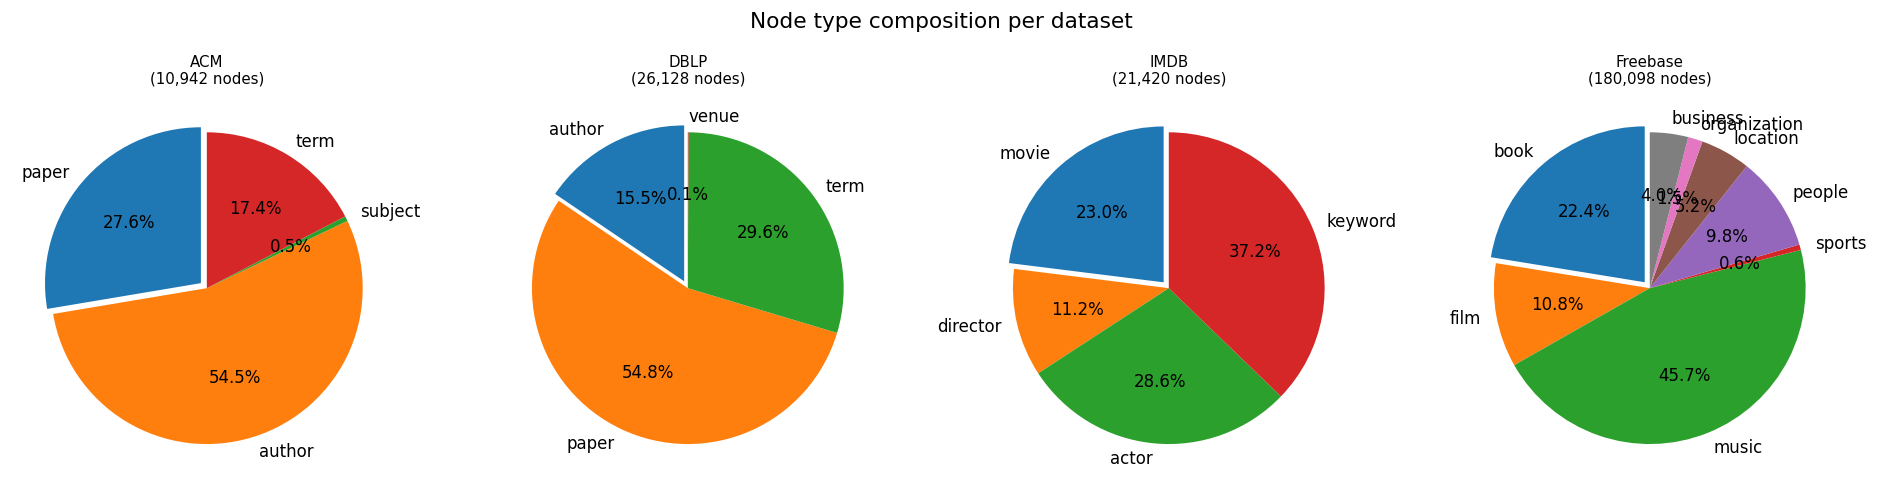

In [9]:
n_ds = len(all_stats)
fig, axes = plt.subplots(1, n_ds, figsize=(4 * n_ds, 4))
fig.suptitle("Node type composition per dataset", fontsize=13, y=1.02)

for ax, (name, s) in zip(axes, all_stats.items()):
    labels = list(s.node_counts.keys())
    sizes = list(s.node_counts.values())
    explode = [0.05 if lbl == s.target_node_type else 0 for lbl in labels]
    wedges, texts, autotexts = ax.pie(
        sizes,
        labels=labels,
        explode=explode,
        autopct="%1.1f%%",
        startangle=90,
        textprops={"fontsize": 10},
    )
    for at in autotexts:
        at.set_fontsize(10)
    ax.set_title(f"{name}\n({s.total_nodes:,} nodes)", fontsize=9)

plt.tight_layout()
plt.savefig("figures/eda_node_composition.png", bbox_inches="tight")
plt.show()

### 3.2 · Edge type counts

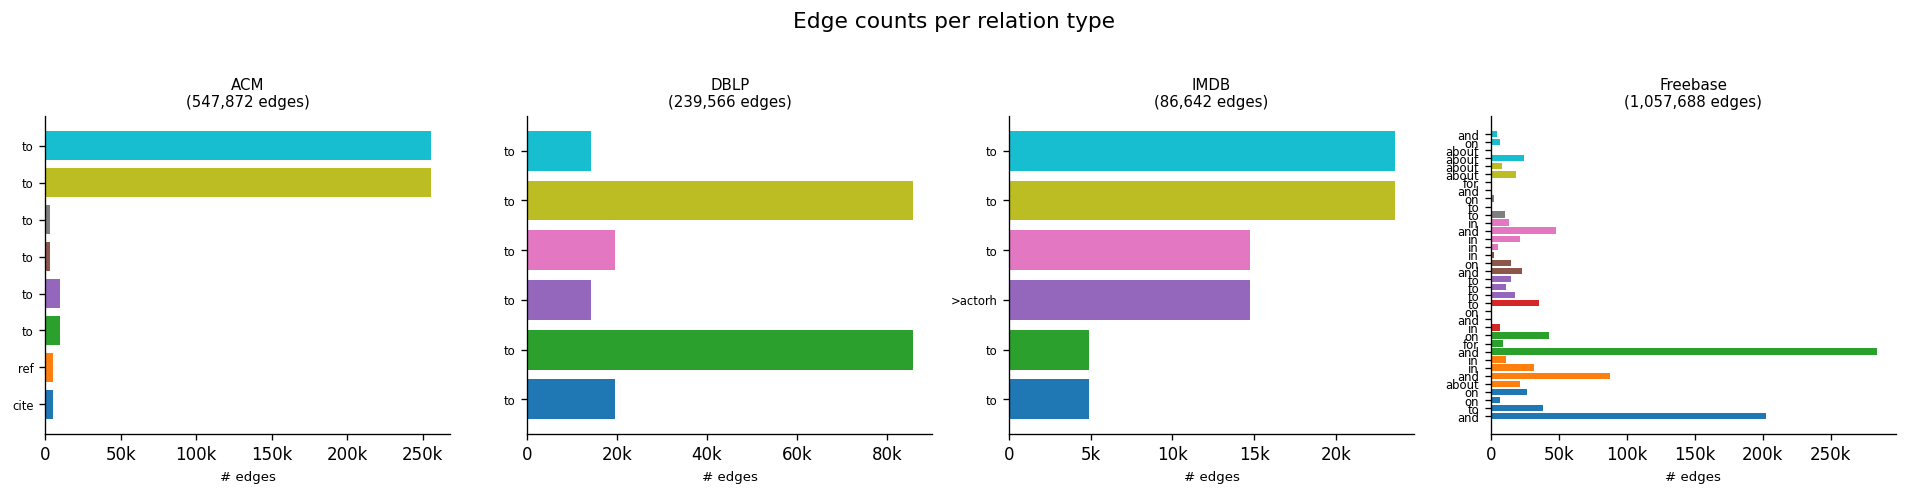

In [10]:
fig, axes = plt.subplots(1, n_ds, figsize=(4 * n_ds, 4))
fig.suptitle("Edge counts per relation type", fontsize=13, y=1.02)

for ax, (name, s) in zip(axes, all_stats.items()):
    # shorten labels: keep only the relation name (middle part)
    short_labels = [et.split("__")[1] for et in s.edge_counts]
    counts = list(s.edge_counts.values())
    colors = plt.cm.tab10(np.linspace(0, 1, len(counts)))
    bars = ax.barh(range(len(counts)), counts, color=colors)
    ax.set_yticks(range(len(counts)))
    ax.set_yticklabels(short_labels, fontsize=7)
    ax.set_xlabel("# edges", fontsize=8)
    ax.set_title(f"{name}\n({s.total_edges:,} edges)", fontsize=9)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else str(int(x))))

plt.tight_layout()
plt.savefig("figures/eda_edge_counts.png", bbox_inches="tight")
plt.show()

### 3.3 · Label distribution

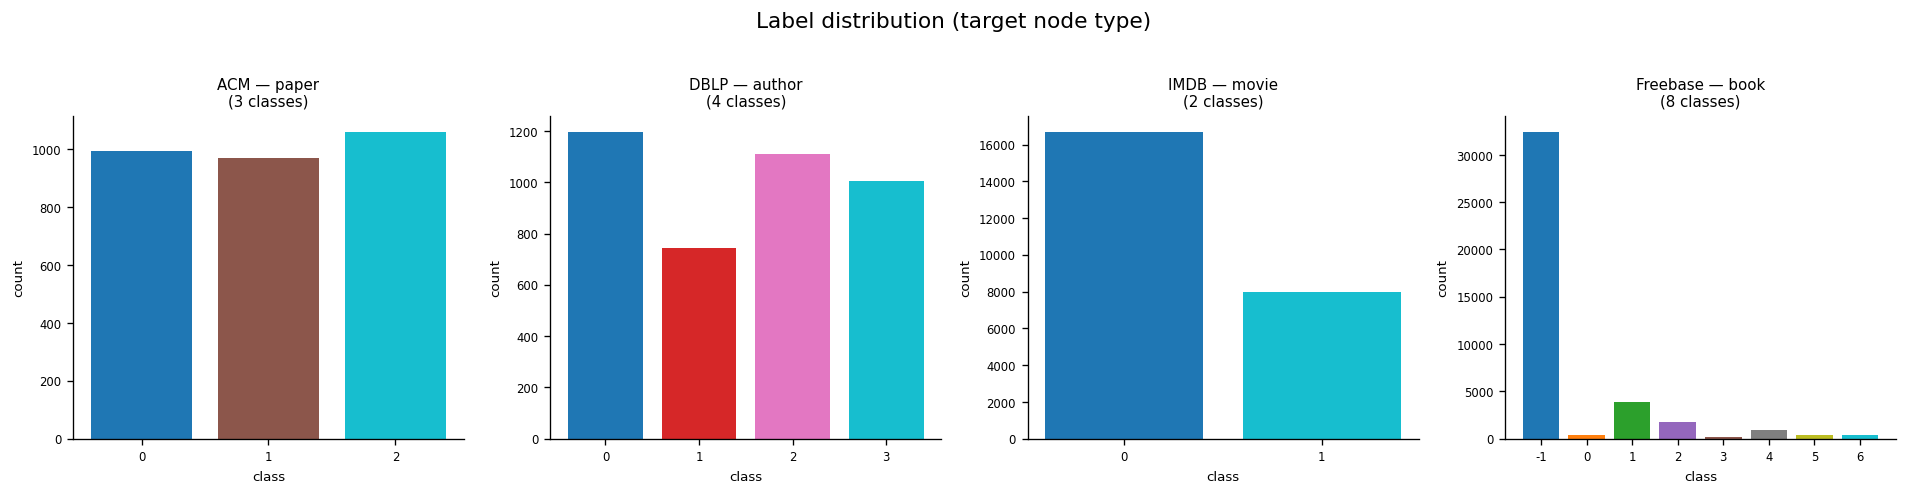

In [11]:
datasets_with_labels = [(name, s) for name, s in all_stats.items() if s.label_dist]
fig, axes = plt.subplots(1, len(datasets_with_labels), figsize=(4 * len(datasets_with_labels), 4))
if len(datasets_with_labels) == 1:
    axes = [axes]
fig.suptitle("Label distribution (target node type)", fontsize=13, y=1.02)

for ax, (name, s) in zip(axes, datasets_with_labels):
    cls_ids = sorted(s.label_dist.keys())
    counts = [s.label_dist[c] for c in cls_ids]
    colors = plt.cm.tab10(np.linspace(0, 1, len(cls_ids)))
    ax.bar([str(c) for c in cls_ids], counts, color=colors)
    ax.set_xlabel("class", fontsize=8)
    ax.set_ylabel("count", fontsize=8)
    ax.set_title(f"{name} — {s.target_node_type}\n({s.num_classes} classes)", fontsize=9)
    ax.tick_params(axis="both", labelsize=7)

plt.tight_layout()
plt.savefig("figures/eda_label_dist.png", bbox_inches="tight")
plt.show()

### 3.4 · Mean degree per relation

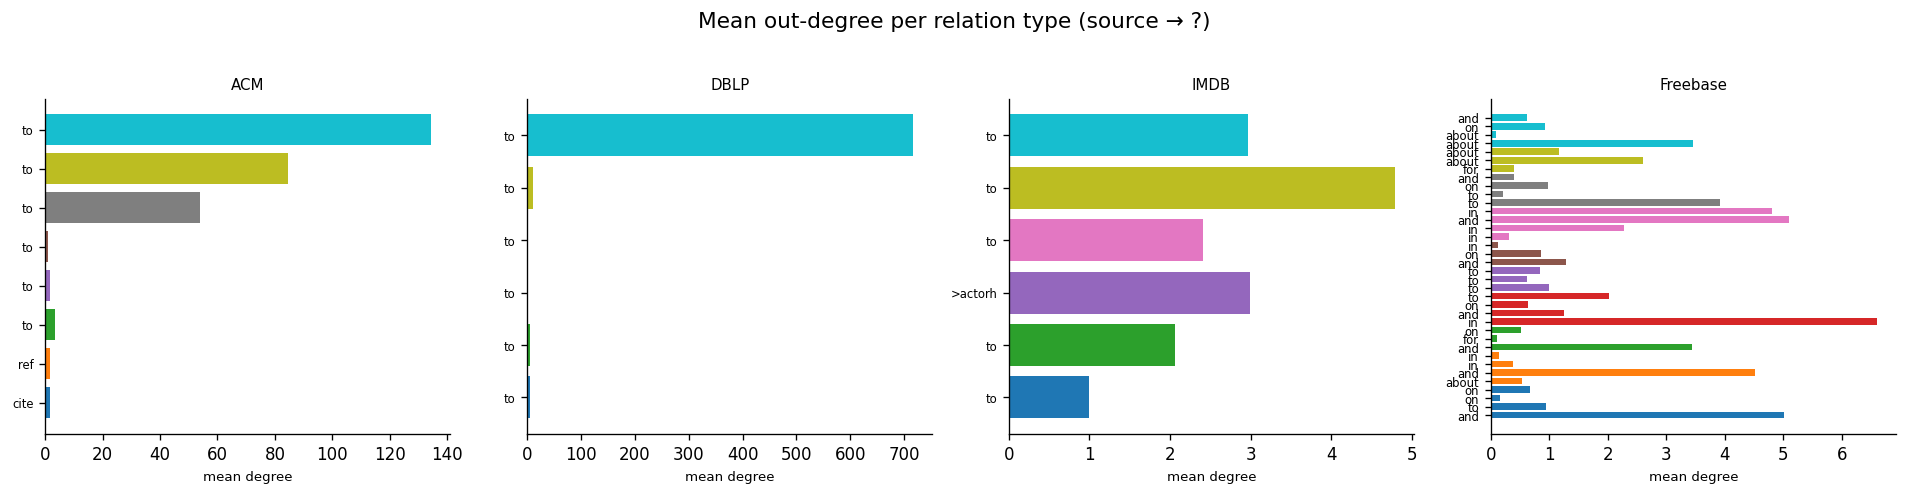

In [12]:
fig, axes = plt.subplots(1, n_ds, figsize=(4 * n_ds, 4))
fig.suptitle("Mean out-degree per relation type (source → ?)", fontsize=13, y=1.02)

for ax, (name, s) in zip(axes, all_stats.items()):
    rels = list(s.degree_stats.keys())
    short = [r.split("__")[1] for r in rels]
    means = [s.degree_stats[r]["mean"] for r in rels]
    colors = plt.cm.tab10(np.linspace(0, 1, len(rels)))
    ax.barh(range(len(rels)), means, color=colors)
    ax.set_yticks(range(len(rels)))
    ax.set_yticklabels(short, fontsize=7)
    ax.set_xlabel("mean degree", fontsize=8)
    ax.set_title(name, fontsize=9)

plt.tight_layout()
plt.savefig("figures/eda_mean_degree.png", bbox_inches="tight")
plt.show()

### 3.5 · Train / val / test split sizes

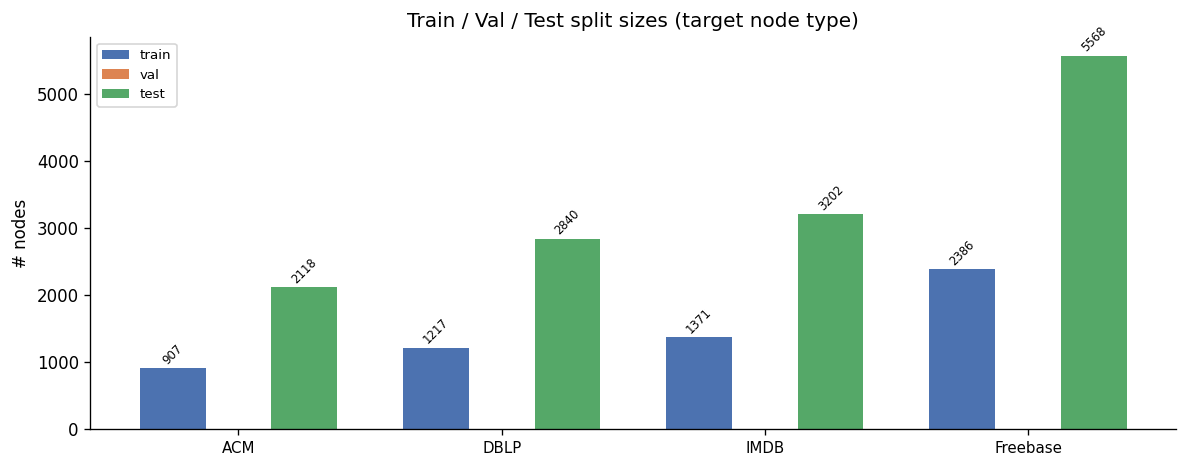

In [13]:
split_names = ["train", "val", "test"]
ds_names = list(all_stats.keys())
x = np.arange(len(ds_names))
width = 0.25
colors = ["#4C72B0", "#DD8452", "#55A868"]

fig, ax = plt.subplots(figsize=(10, 4))
for i, (split, color) in enumerate(zip(split_names, colors)):
    counts = [all_stats[n].split_sizes[split] for n in ds_names]
    bars = ax.bar(x + i * width, counts, width, label=split, color=color)
    for bar, cnt in zip(bars, counts):
        if cnt > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 20,
                str(cnt),
                ha="center", va="bottom", fontsize=7, rotation=45,
            )

ax.set_xticks(x + width)
ax.set_xticklabels(ds_names, fontsize=9)
ax.set_ylabel("# nodes")
ax.set_title("Train / Val / Test split sizes (target node type)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/eda_splits.png", bbox_inches="tight")
plt.show()

### 3.6 · Feature dimension heatmap

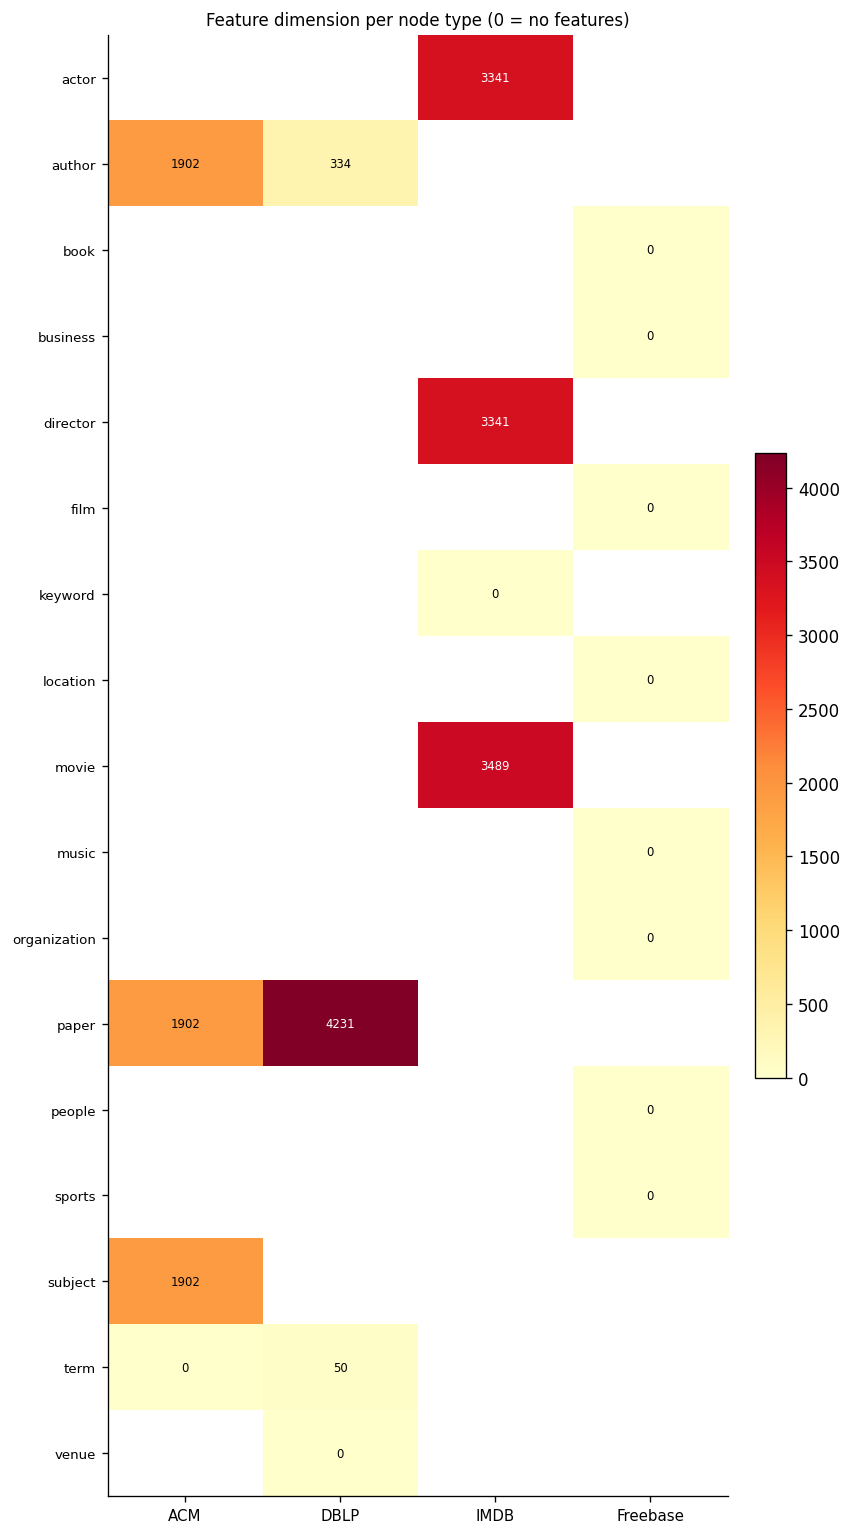

In [14]:
# collect all node types across datasets
all_node_types = sorted({nt for s in all_stats.values() for nt in s.node_feat_dims})
ds_names = list(all_stats.keys())

matrix = np.zeros((len(all_node_types), len(ds_names)))
for j, ds_name in enumerate(ds_names):
    for i, nt in enumerate(all_node_types):
        matrix[i, j] = all_stats[ds_name].node_feat_dims.get(nt, np.nan)

fig, ax = plt.subplots(figsize=(len(ds_names) * 1.8, len(all_node_types) * 0.7 + 1))
im = ax.imshow(matrix, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(ds_names)))
ax.set_xticklabels(ds_names, fontsize=9)
ax.set_yticks(range(len(all_node_types)))
ax.set_yticklabels(all_node_types, fontsize=8)
ax.set_title("Feature dimension per node type (0 = no features)", fontsize=10)

for i in range(len(all_node_types)):
    for j in range(len(ds_names)):
        v = matrix[i, j]
        if not np.isnan(v):
            ax.text(j, i, str(int(v)), ha="center", va="center", fontsize=7,
                    color="white" if v > matrix[~np.isnan(matrix)].max() * 0.6 else "black")

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("figures/eda_feat_dims.png", bbox_inches="tight")
plt.show()

### 3.7 · Degree distribution histograms (target node type)

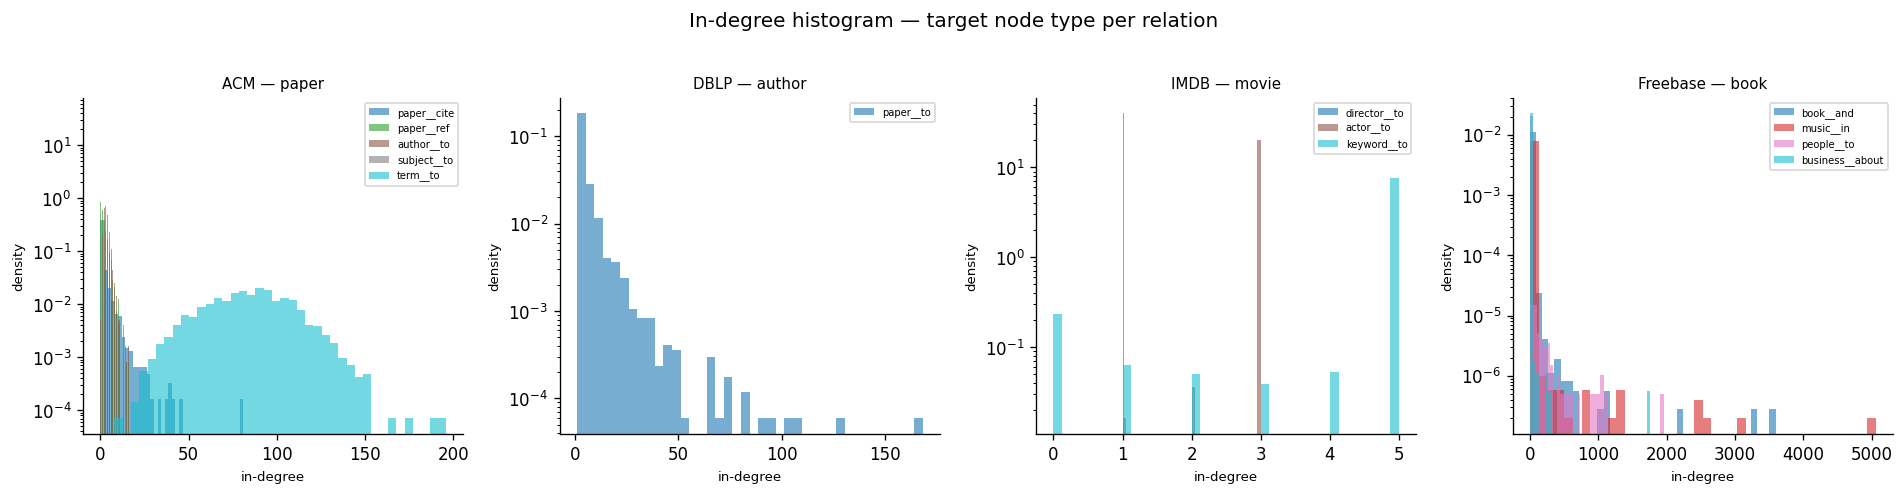

In [15]:
def _degree_for_target(
    data: HeteroData,
    target: str,
    node_counts: dict[str, int],
) -> dict[str, np.ndarray]:
    """Return in-degree arrays (keyed by relation) for the target node type."""
    result: dict[str, np.ndarray] = {}
    for et in data.edge_types:
        if str(et[2]) != target:
            continue
        key = f"{et[0]}__{et[1]}"
        n_target = node_counts[target]
        ei = data[et].edge_index
        deg = torch.zeros(n_target, dtype=torch.long)
        deg.scatter_add_(0, ei[1], torch.ones(ei.size(1), dtype=torch.long))
        result[key] = deg.numpy()
    return result


fig, axes = plt.subplots(1, n_ds, figsize=(4 * n_ds, 4))
fig.suptitle("In-degree histogram — target node type per relation", fontsize=12, y=1.02)

for ax, (name, (data, target)) in zip(axes, DATASETS.items()):
    s = all_stats[name]
    deg_arrays = _degree_for_target(data, target, s.node_counts)
    if not deg_arrays:
        ax.set_title(f"{name}\n(no incoming edges)", fontsize=9)
        continue
    colors = plt.cm.tab10(np.linspace(0, 1, len(deg_arrays)))
    for (rel, deg), color in zip(deg_arrays.items(), colors):
        ax.hist(deg, bins=40, alpha=0.6, label=rel, color=color, density=True)
    ax.set_xlabel("in-degree", fontsize=8)
    ax.set_ylabel("density", fontsize=8)
    ax.set_title(f"{name} — {target}", fontsize=9)
    ax.legend(fontsize=6)
    ax.set_yscale("log")

plt.tight_layout()
plt.savefig("figures/eda_degree_hist.png", bbox_inches="tight")
plt.show()

## 4 · Comparative Summary Table

In [16]:
rows = []
for name, s in all_stats.items():
    node_type_str = ", ".join(f"{nt}({n:,})" for nt, n in s.node_counts.items())
    feat_str = ", ".join(
        f"{nt}:{d}" for nt, d in s.node_feat_dims.items() if d > 0
    ) or "none"
    rows.append({
        "Dataset": name,
        "Target node": s.target_node_type,
        "Node types": s.num_node_types,
        "Edge types": s.num_edge_types,
        "Total nodes": f"{s.total_nodes:,}",
        "Total edges": f"{s.total_edges:,}",
        "Classes": s.num_classes,
        "Train / Val / Test": "{} / {} / {}".format(
            s.split_sizes["train"],
            s.split_sizes["val"],
            s.split_sizes["test"],
        ),
        "Node type breakdown": node_type_str,
        "Feature dims": feat_str,
    })

df_summary = pd.DataFrame(rows).set_index("Dataset")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
print(df_summary.to_string())
df_summary

         Target node  Node types  Edge types Total nodes Total edges  Classes Train / Val / Test                                                                                                              Node type breakdown                           Feature dims
Dataset                                                                                                                                                                                                                                                                 
ACM            paper           4           8      10,942     547,872        3     907 / 0 / 2118                                                                            paper(3,025), author(5,959), subject(56), term(1,902)  paper:1902, author:1902, subject:1902
DBLP          author           4           6      26,128     239,566        4    1217 / 0 / 2840                                                                             author(4,057), paper(14,328), te

,Target node,Node types,Edge types,Total nodes,Total edges,Classes,Train / Val / Test,Node type breakdown,Feature dims
Dataset,,,,,,,,,
ACM,paper,4,8,"10,942","547,872",3,907 / 0 / 2118,"paper(3,025), author(5,959), subject(56), term(1,902)","paper:1902, author:1902, subject:1902"
DBLP,author,4,6,"26,128","239,566",4,1217 / 0 / 2840,"author(4,057), paper(14,328), term(7,723), venue(20)","author:334, paper:4231, term:50"
IMDB,movie,4,6,"21,420","86,642",2,1371 / 0 / 3202,"movie(4,932), director(2,393), actor(6,124), keyword(7,971)","movie:3489, director:3341, actor:3341"
Freebase,book,8,36,"180,098","1,057,688",8,2386 / 0 / 5568,"book(40,402), film(19,427), music(82,351), sports(1,025), people(17,641), lo...",none


## 5 · Degree Statistics Table (per relation)

In [17]:
deg_rows = []
for name, s in all_stats.items():
    for rel, stats in s.degree_stats.items():
        src_type, rel_name, dst_type = rel.split("__")
        deg_rows.append({
            "Dataset": name,
            "Relation": rel_name,
            "Src type": src_type,
            "Dst type": dst_type,
            "Mean deg": f"{stats['mean']:.2f}",
            "Median deg": f"{stats['median']:.0f}",
            "Max deg": f"{stats['max']:.0f}",
            "Min deg": f"{stats['min']:.0f}",
        })

df_deg = pd.DataFrame(deg_rows)
print(df_deg.to_string(index=False))
df_deg

 Dataset Relation     Src type     Dst type Mean deg Median deg Max deg Min deg
     ACM     cite        paper        paper     1.77          1      16       0
     ACM      ref        paper        paper     1.77          0      81       0
     ACM       to        paper       author     3.29          3      16       0
     ACM       to       author        paper     1.67          1      50       1
     ACM       to        paper      subject     1.00          1       1       1
     ACM       to      subject        paper    54.02          5    1195       1
     ACM       to        paper         term    84.50         85     196       8
     ACM       to         term        paper   134.39         60    3001       2
    DBLP       to       author        paper     4.84          2     168       1
    DBLP       to        paper         term     5.99          6      19       0
    DBLP       to        paper        venue     1.00          1       1       1
    DBLP       to        paper       aut

,Dataset,Relation,Src type,Dst type,Mean deg,Median deg,Max deg,Min deg
0,ACM,cite,paper,paper,1.77,1,16,0
1,ACM,ref,paper,paper,1.77,0,81,0
2,ACM,to,paper,author,3.29,3,16,0
3,ACM,to,author,paper,1.67,1,50,1
4,ACM,to,paper,subject,1.00,1,1,1
5,ACM,to,subject,paper,54.02,5,1195,1
6,ACM,to,paper,term,84.50,85,196,8
7,ACM,to,term,paper,134.39,60,3001,2
8,DBLP,to,author,paper,4.84,2,168,1
9,DBLP,to,paper,term,5.99,6,19,0


## 6 · Feature Statistics (target node type)

In [18]:
feat_rows = []
for name, (data, target) in DATASETS.items():
    x = getattr(data[target], "x", None)
    if x is None or x.size(1) == 0:
        feat_rows.append({
            "Dataset": name, "Node type": target,
            "Feat dim": 0, "Mean": "—", "Std": "—",
            "Min": "—", "Max": "—", "Sparsity %": "—",
        })
        continue
    x_f = x.float()
    sparsity = float((x_f == 0).float().mean() * 100)
    feat_rows.append({
        "Dataset":    name,
        "Node type":  target,
        "Feat dim":   x_f.size(1),
        "Mean":       f"{x_f.mean():.4f}",
        "Std":        f"{x_f.std():.4f}",
        "Min":        f"{x_f.min():.4f}",
        "Max":        f"{x_f.max():.4f}",
        "Sparsity %": f"{sparsity:.1f}",
    })

df_feat = pd.DataFrame(feat_rows).set_index("Dataset")
print(df_feat.to_string())
df_feat

         Node type  Feat dim    Mean     Std       Min      Max Sparsity %
Dataset                                                                   
ACM          paper      1902  0.0444  0.2060    0.0000   1.0000       95.6
DBLP        author       334  0.0360  0.1863    0.0000   1.0000       96.4
IMDB         movie      3489  0.0031  0.0890  -34.2851  61.4230       99.2
Freebase      book         0       —       —         —        —          —


,Node type,Feat dim,Mean,Std,Min,Max,Sparsity %
Dataset,,,,,,,
ACM,paper,1902,0.0444,0.2060,0.0000,1.0000,95.6
DBLP,author,334,0.0360,0.1863,0.0000,1.0000,96.4
IMDB,movie,3489,0.0031,0.0890,-34.2851,61.4230,99.2
Freebase,book,0,—,—,—,—,—


## 7 · Homophily Ratio (target node type)

For each relation type `r` that connects two nodes of the same type as the target,
compute the edge homophily ratio:

$$h_r = \frac{\lvert \{(u,v) \in E_r : y_u = y_v\} \rvert}{\lvert E_r \rvert}$$

In [19]:
hom_rows = []
for name, (data, target) in DATASETS.items():
    y_target = getattr(data[target], "y", None)
    if y_target is None:
        continue
    y_target = y_target.view(-1).long()

    for et in data.edge_types:
        src_type, rel_name, dst_type = [str(t) for t in et]
        if src_type != target or dst_type != target:
            continue
        ei = data[et].edge_index
        src_labels = y_target[ei[0]]
        dst_labels = y_target[ei[1]]
        h = float((src_labels == dst_labels).float().mean().item())
        hom_rows.append({
            "Dataset": name,
            "Relation": f"{src_type}__{rel_name}__{dst_type}",
            "# edges": int(ei.size(1)),
            "Homophily": f"{h:.4f}",
        })

if hom_rows:
    df_hom = pd.DataFrame(hom_rows)
    print(df_hom.to_string(index=False))
    display(df_hom)
else:
    print("No same-type self-relations found among the target node types in these datasets.")
    print("Homophily is typically measured on homogeneous projections (e.g. meta-path graphs).")

 Dataset           Relation  # edges Homophily
     ACM paper__cite__paper     5343    0.8797
     ACM  paper__ref__paper     5343    0.8797
Freebase    book__and__book   202674    0.6035


,Dataset,Relation,# edges,Homophily
0,ACM,paper__cite__paper,5343,0.8797
1,ACM,paper__ref__paper,5343,0.8797
2,Freebase,book__and__book,202674,0.6035


## 8 · Export Summary CSVs

In [20]:
out_dir = PROJECT_DIR / "experiments" / "eda"
out_dir.mkdir(parents=True, exist_ok=True)

df_summary.to_csv(out_dir / "dataset_summary.csv")
df_deg.to_csv(out_dir / "degree_stats.csv", index=False)
df_feat.to_csv(out_dir / "feature_stats.csv")

print(f"CSVs saved to {out_dir}")
for f in sorted(out_dir.iterdir()):
    print(" ", f.name)

CSVs saved to /content/drive/MyDrive/H2S-NN_test/experiments/eda
  dataset_summary.csv
  degree_stats.csv
  feature_stats.csv
